In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset (1).csv')

In [ ]:
df = df.drop([ 'PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, errors='ignore')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

In [ ]:
x=df[['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
y=df[['Survived']]

In [ ]:
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(x_tr, y_tr.values.ravel())
y_pred = clf.predict(x_te)

In [ ]:
print("Accuracy: ", round(accuracy_score(y_te, y_pred), 2))
print("Precision: ", round(precision_score(y_te, y_pred), 2))
print("Recall: ", round(recall_score(y_te, y_pred), 2))
print("F1 Score: ", round(f1_score(y_te, y_pred), 2))
print("Classification Report:\n", classification_report(y_te, y_pred))

Accuracy:  0.8
Precision:  0.77
Recall:  0.73
F1 Score:  0.75
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Confusion Matrix:
 [[89 16]
 [20 54]]


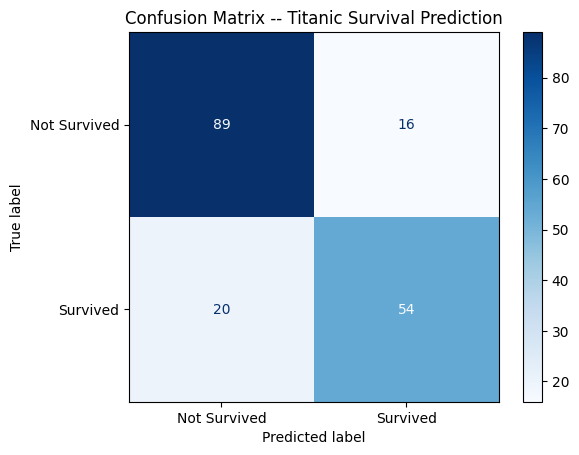

In [ ]:
cr = confusion_matrix(y_te, y_pred, labels=[0,1])
print("Confusion Matrix:\n",cr)
disp = ConfusionMatrixDisplay(confusion_matrix=cr, display_labels=["Not Survived","Survived"]).plot(cmap="Blues")
plt.title("Confusion Matrix -- Titanic Survival Prediction")
plt.show()